In [1]:
import matplotlib.pyplot as plt
import numpy as np
import itertools
import random
import json
import os

In [2]:
class ExpInfo:
    def __init__(self, name: str, where: str, json_name: str):
        self.name = name
        self.json_name =\
            os.path.join("/home/vlad/Documents/SublimeMerge/dragonfly-scripts/server_mirror/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/",
                         json_name)\
            if where == "fep" else\
            os.path.join("/home/vlad/Documents/SublimeMerge/dragonfly-scripts/uet-htsim/htsim/sim/datacenter/dragonfly_plus_experiments/jsons/",
                         json_name)
        self.where = where
        
    def __repr__(self):
        return f"{self.name = }, {self.json_name = }, {self.where = }"

In [6]:
ht_k_scores = {
     4: [('0', 'best'), ('-6', 'random'), ('-8', 'default')],
     6: [('0', 'best'), ('-40', 'random'), ('-108', 'default')],
     8: [('-14', 'best'), ('-138', 'random'), ('-576', 'default')],
}

In [5]:
exps = """
partial_all_to_all parallel K = 6 # used groups = 3/10, fep, partial_all_to_all_1775338664.json
partial_all_to_all parallel K = 6 # used groups = 5/10, fep, partial_all_to_all_1775345622.json
partial_all_to_all parallel K = 6 # used groups = 7/10, fep, partial_all_to_all_1775341754.json
partial_all_to_all parallel K = 6 # used groups = 10/10, fep, full_all_to_all_1780138408.json
partial_all_to_all parallel K = 8 # used groups = 4/17, fep, partial_all_to_all_1775355146.json
partial_all_to_all parallel K = 8 # used groups = 8/17, fep, partial_all_to_all_1775378698.json
partial_all_to_all parallel K = 8 # used groups = 13/17, fep, partial_all_to_all_1775460491.json
partial_all_to_all parallel K = 8 # used groups = 17/17, fep, full_all_to_all_1780150049.json
"""

exps = list(map(lambda x: ExpInfo(*x.split(", ")), exps.split('\n')[1:-1]))

ht_exps = {exp.name: exp.json_name for exp in exps}

In [27]:
def get_mean_fct(exp_name):
    with open(ht_exps[exp_name]) as fin:
        ht = json.load(fin)
    
    k = ht["K"]
    best_score = ht_k_scores[k][0][0]
    return ht[best_score]["mean_fcts"][-1]

In [31]:
BASE_FCT = 180

def get_th_exp_oversub(h, cnt_used_groups):
    return 2 * (cnt_used_groups * h**2 - 1)

In [37]:
ht = {"th": {6: [], 8: []}, "obs": {6: [], 8: []}}

for k, arr_cnt_used_groups in [(6, [3, 5, 7, 10]), (8, [4, 8, 13, 17])]:
    h = k // 2
    for cnt_used_groups in arr_cnt_used_groups:
        th_exp_oversub = get_th_exp_oversub(h, cnt_used_groups)
        obs_exp_oversub = get_mean_fct(f"partial_all_to_all parallel K = {k} # used groups = {cnt_used_groups}/{h**2+1}") / BASE_FCT
        
        ht["th"][k].append((cnt_used_groups, th_exp_oversub))
        ht["obs"][k].append((cnt_used_groups, obs_exp_oversub))
        
        print(f"{k = }, {cnt_used_groups = }, {th_exp_oversub = }, {obs_exp_oversub = }")

k = 6, cnt_used_groups = 3, th_exp_oversub = 52, obs_exp_oversub = 28.158902836879452
k = 6, cnt_used_groups = 5, th_exp_oversub = 88, obs_exp_oversub = 55.3249486111111
k = 6, cnt_used_groups = 7, th_exp_oversub = 124, obs_exp_oversub = 92.56672222222224
k = 6, cnt_used_groups = 10, th_exp_oversub = 178, obs_exp_oversub = 156.3451111111111
k = 8, cnt_used_groups = 4, th_exp_oversub = 126, obs_exp_oversub = 67.10780045351474
k = 8, cnt_used_groups = 8, th_exp_oversub = 254, obs_exp_oversub = 168.5115811965812
k = 8, cnt_used_groups = 13, th_exp_oversub = 414, obs_exp_oversub = 368.9409722222221
k = 8, cnt_used_groups = 17, th_exp_oversub = 542, obs_exp_oversub = 601.7277777777778


In [38]:
ht

{'th': {6: [(3, 52), (5, 88), (7, 124), (10, 178)],
  8: [(4, 126), (8, 254), (13, 414), (17, 542)]},
 'obs': {6: [(3, 28.158902836879452),
   (5, 55.3249486111111),
   (7, 92.56672222222224),
   (10, 156.3451111111111)],
  8: [(4, 67.10780045351474),
   (8, 168.5115811965812),
   (13, 368.9409722222221),
   (17, 601.7277777777778)]}}

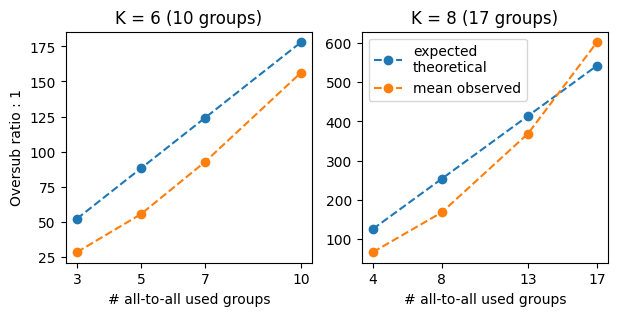

In [55]:
fig, ax = plt.subplots(1, 2, figsize = (7, 3))

for i, k in zip(range(2), [6, 8]):
    for arr in [ht["th"][k], ht["obs"][k]]:
        arr_cg = [x for x, _ in arr]
        arr_oversubs = [x for _, x in arr]
        ax[i].plot(arr_cg, arr_oversubs, ls = '--', marker = 'o')
        ax[i].set_xticks(arr_cg)
        
    ax[i].set_xlabel("# all-to-all used groups")
    if i == 1:
        ax[i].legend(["expected\ntheoretical", "mean observed"])

    ax[i].set_title(f"K = {k} ({k**2//4+1} groups)")

ax[0].set_ylabel("Oversub ratio : 1")

fig.savefig(
    f"/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/partial_all_to_all_expected_oversub.pdf",
    bbox_inches = "tight", pad_inches = 1e-2
)